# V-JEPA: predict masked spatio-temporal tubes of a video

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/vision/vjepa.ipynb)

[V-JEPA](https://arxiv.org/abs/2404.08471) ([code](https://github.com/facebookresearch/jepa)) learns from video by predicting, in feature space, the parts of a clip it cannot see. The hidden parts are tubes that span time, and the targets are the features of an EMA copy of the encoder. [V-JEPA 2](https://arxiv.org/abs/2506.09985) ([code](https://github.com/facebookresearch/vjepa2)) keeps the objective and adds 3D RoPE (`use_rope=True`), which we use here.

In [ ]:
import importlib.util
import os
import urllib.request

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"
    os.makedirs("assets", exist_ok=True)
    for name in ["street.mp4"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/latent-horizon/pytorch-world/main/examples/vision/assets/{name}", f"assets/{name}")

In [2]:
import torch
import torch.nn.functional as F
from matplotlib import colormaps

from torch_world import metrics, plots
from torch_world.datasets import random_clips, read_video
from torch_world.masks import MultiBlock3DMask
from torch_world.models import VJEPA
from torch_world.nn import MaskedPredictor, VisionTransformer
from torch_world.utils import linear_schedule

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
FRAMES, STEPS = 8, 3000

## The street
A London street filmed from a fixed camera, with buses and cabs driving through. A clip is a fixed 96 px window of it, 8 frames long, every second frame of the footage, as the camera saw it: the street stays put and the traffic moves.

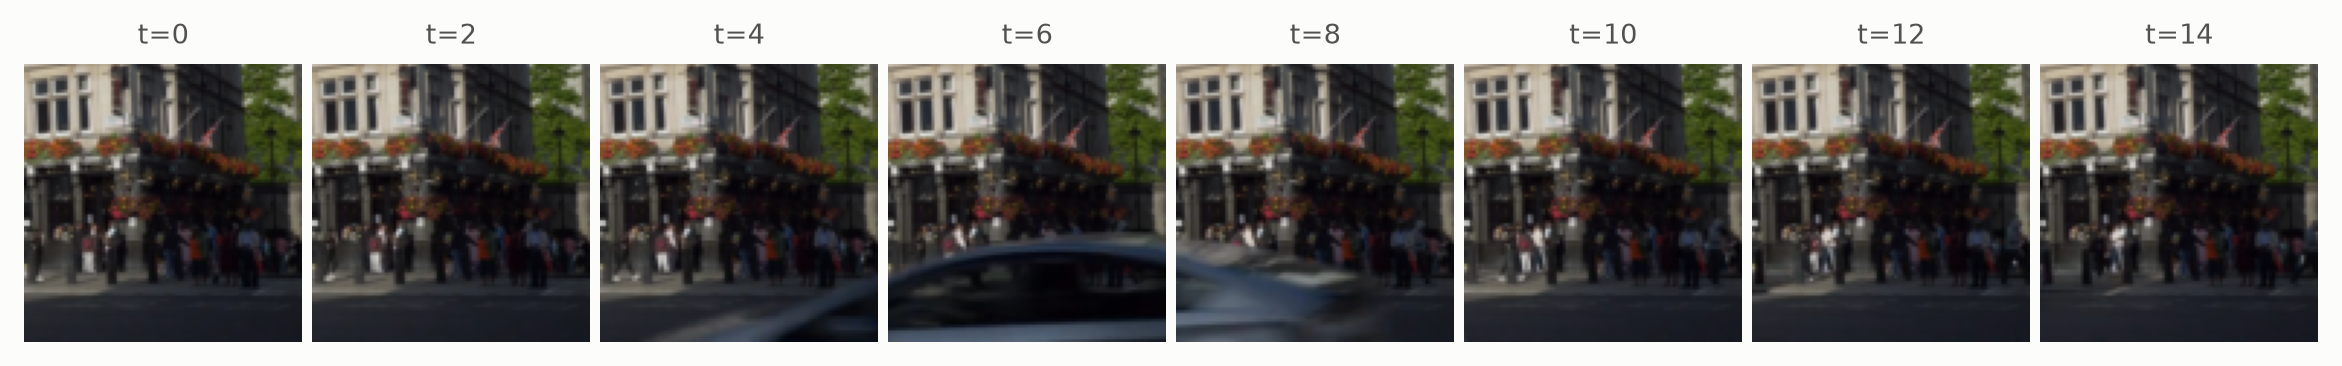

In [3]:
street = read_video("assets/street.mp4", size=(216, 384), device=device)


def clips(n, generator=None):
    return random_clips(street, n, length=FRAMES, size=96, stride=2, generator=generator)


plots.images(clips(1, torch.Generator().manual_seed(1))[0].transpose(0, 1).cpu(), [f"t={2 * t}" for t in range(FRAMES)])

## Tube masks
A tube masks the same region in every frame, so the model cannot copy a hidden patch from a neighbouring frame. Two strategies run together, as in V-JEPA 2: many small short-range tubes and a few large long-range ones. Each strategy hides its tubes from the encoder, and the predictor fills them in.

In [4]:
vit = dict(img_size=96, patch_size=8, embed_dim=192, depth=6, num_heads=6, num_frames=FRAMES, use_rope=True)
grid = (FRAMES // 2, 12, 12)  # tubelets of 2 frames, 12 x 12 patches
maskers = [
    MultiBlock3DMask(grid, spatial_scale=(0.15, 0.15), num_blocks=8),
    MultiBlock3DMask(grid, spatial_scale=(0.7, 0.7), num_blocks=2),
]


def masks(n):
    pairs = [masker(n) for masker in maskers]
    return [enc.to(device) for (enc,), _ in pairs], [pred.to(device) for _, (pred,) in pairs]

## Train
A 6-block ViT and a 4-block predictor. The loss is the L1 distance between predicted and target features of the masked tubes; the target encoder follows the encoder by EMA.

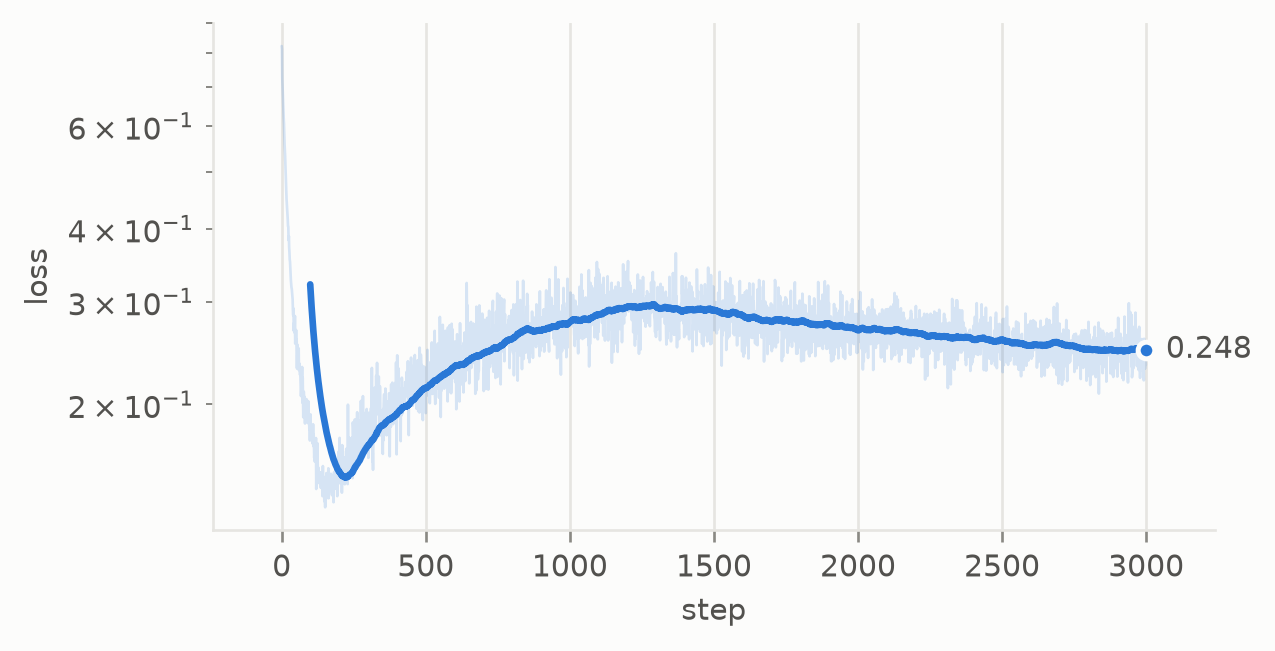

In [5]:
model = VJEPA(VisionTransformer(**vit), MaskedPredictor(grid, 192, 96, depth=4, num_heads=6, num_mask_tokens=2, zero_init_mask_tokens=True, use_rope=True)).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.04)
log = {"L1": []}
for step in range(STEPS):
    loss = model(clips(32), *masks(32))["loss"]
    opt.zero_grad()
    loss.backward()
    opt.step()
    model.update_target(linear_schedule(0.998, 1.0, step, STEPS))
    log["L1"].append(loss.item())
plots.curves(log, smooth=100)

## What the features know
Frozen target encoders on 2048 fresh clips (1536 to fit, 512 to test), against the same ViT at random initialization:
- **attentive probe**, V-JEPA's evaluation: a learned query cross-attends to all tokens and classifies how busy the clip is (still, some traffic, a lot: terciles of how much its pixels change; chance is 33%);
- **dense probe**: from each token alone, a linear map regresses how much its own patch changes over its 2 frames, scored by R². This asks every token to know where things move;
- **RankMe**: the effective rank of the tokens, out of 192 dimensions, after removing their mean.

In [6]:
test = clips(2048, torch.Generator().manual_seed(7))
change = (test[:, :, 1:] - test[:, :, :-1]).abs().mean(1)  # (N, 7, 96, 96)
motion = F.avg_pool3d(torch.cat([change, change[:, -1:]], 1)[:, None], (2, 8, 8)).flatten(1)  # (N, 576), one per token
busy = torch.bucketize(motion.mean(1), motion.mean(1).quantile(torch.tensor([1 / 3, 2 / 3], device=device)))


def scores(encoder):
    with torch.no_grad():
        tokens = torch.cat([encoder(c) for c in test.split(256)])
    attentive = metrics.attentive_probe(tokens[:1536], busy[:1536], tokens[1536:], busy[1536:], epochs=30, lr=3e-3, generator=torch.Generator().manual_seed(0))
    dense = metrics.linear_probe(tokens[:1536].flatten(0, 1), motion[:1536].flatten()[:, None], tokens[1536:].flatten(0, 1), motion[1536:].flatten()[:, None])
    return attentive.score, dense.score, metrics.rankme(tokens.flatten(0, 1), center=True)

In [7]:
print(f"{'':12s}{'attentive probe':>17s}{'dense probe R²':>16s}{'RankMe':>9s}")
for name, encoder in {"random init": VisionTransformer(**vit).to(device), "V-JEPA": model.target_encoder}.items():
    attentive, dense, rank = scores(encoder)
    print(f"{name:12s}{attentive:17.1%}{dense:16.3f}{rank:9.1f}")

              attentive probe  dense probe R²   RankMe


random init             90.0%           0.435     83.7


V-JEPA                  82.0%           0.257     29.1


## Patch features on the street
The whole street at 216 x 384 (27 x 48 patches), where training saw 96 px windows of it: with RoPE, the encoder takes positions from the input's own grid. It reads 8 frames at a time, the clip length it was trained on, and gives one token per 8 x 8 patch and 2 frames. One PCA is fitted over every token, so a color means the same thing throughout.

Left to right: the footage; the three leading principal components of the frozen tokens, as RGB; and how far each patch token moves from the previous 2 frames. The PCA mostly colors the layout of the street, and stays put from frame to frame. The token change lights up the buses and cars and stays dark on the static street; it follows where the pixels change (correlation printed below), so these small features respond to motion more than they identify objects.

In [8]:
def patch_tokens(encoder, frames):
    """Patch tokens (T / 2, h, w, D) of frames (T, 3, H, W): one per tubelet of 2 frames, encoded FRAMES at a time."""
    with torch.no_grad():
        tokens = torch.cat([encoder(clip.transpose(0, 1)[None])[0] for clip in frames.split(FRAMES)])
    return tokens.view(-1, frames.size(-2) // 8, frames.size(-1) // 8, tokens.size(-1))


frames = street[::2]
frames = frames[: len(frames) // FRAMES * FRAMES]  # (T, 3, 216, 384)
size = frames.shape[-2:]
tokens = patch_tokens(model.target_encoder, frames)

change = (tokens[1:] - tokens[:-1]).norm(dim=-1)
pixels = F.avg_pool2d((frames[2::2] - frames[:-2:2]).abs().mean(1, keepdim=True), 8)[:, 0]
print(f"correlation of token change with pixel change: {torch.corrcoef(torch.stack([change.flatten(), pixels.flatten()]))[0, 1]:.2f}")

change = torch.cat([change[:1], change])  # the first tubelet repeats the second's change
heat = torch.from_numpy(colormaps["magma"]((change / change.quantile(0.995)).clamp(0, 1).cpu().numpy())[..., :3])
heat = F.interpolate(heat.permute(0, 3, 1, 2).float(), size=size)
plots.video(frames, plots.pca_colors(tokens, size).repeat_interleave(2, 0), heat.repeat_interleave(2, 0))

correlation of token change with pixel change: 0.45


## Summary
V-JEPA never reconstructs a pixel: it predicts the features of hidden tubes. On the street, the probes read from the frozen tokens how busy a clip is and which patches move. [V-JEPA 2.1](vjepa21.ipynb) trains the same way with two more losses that make each patch token useful on its own.